# 04 — Experimentos 2 e 3: MobileNetV2 pré-treinado + cabeça, e hiperparâmetros

Backbone ImageNet **congelado** (TFLite INT8) → características → cabeça supervisionada treinada no PlantVillage. Hiperparâmetros escolhidos na **validação**; o teste só é relatado ao final.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
M = ROOT / 'results' / 'metrics'
def show(name): display(Image(filename=str(ROOT / 'results' / name), width=620))


In [2]:
display(pd.DataFrame(json.load(open(M/'exp2_feature_sets.json')))); display(pd.DataFrame(json.load(open(M/'exp3_hyperparameters.json'))))

,feature_set,dim,head,val_f1_macro,test_accuracy,test_f1_macro,plantdoc_accuracy,deployed_representation
0,final,1280,LogReg C=0.1,0.9486,0.9508,0.9500,0.4147,False
1,multiscale,1984,LogReg C=0.1,0.9721,0.9772,0.9767,0.4215,True
2,multiscale+handcrafted,2014,LogReg C=0.1,0.9719,0.9790,0.9787,0.4164,False


,config_name,val_accuracy,val_f1_macro,test_accuracy,test_f1_macro,training_time_sec,selected_by_validation,plantdoc_accuracy,deployed
0,LogReg C=0.0001,0.9344,0.9291,0.9435,0.9405,1.231,False,0.3976,NaN
1,LogReg C=0.001,0.9644,0.9625,0.9690,0.9678,1.487,False,0.4147,NaN
2,LogReg C=0.01,0.9708,0.9696,0.9745,0.9736,0.916,False,0.4164,NaN
3,LogReg C=0.1,0.9736,0.9721,0.9772,0.9767,0.573,True,0.4215,NaN
4,LogReg C=1,0.9717,0.9703,0.9772,0.9765,0.404,False,0.3720,NaN
5,LogReg C=10,0.9717,0.9703,0.9790,0.9785,0.385,False,0.3498,NaN
6,MLP (256) lr=1e-3,0.9690,0.9670,0.9717,0.9711,4.336,False,0.4044,NaN
7,"MLP (512,128) lr=1e-3",0.9608,0.9593,0.9736,0.9736,6.819,False,0.3874,NaN
8,MLP (256) lr=5e-2 (instável),0.9562,0.9537,0.9699,0.9685,5.374,False,0.4010,NaN
9,LogReg C=0.1 + aumento de dados (2 cópias),0.9717,0.9701,0.9763,0.9752,NaN,NaN,0.4386,True


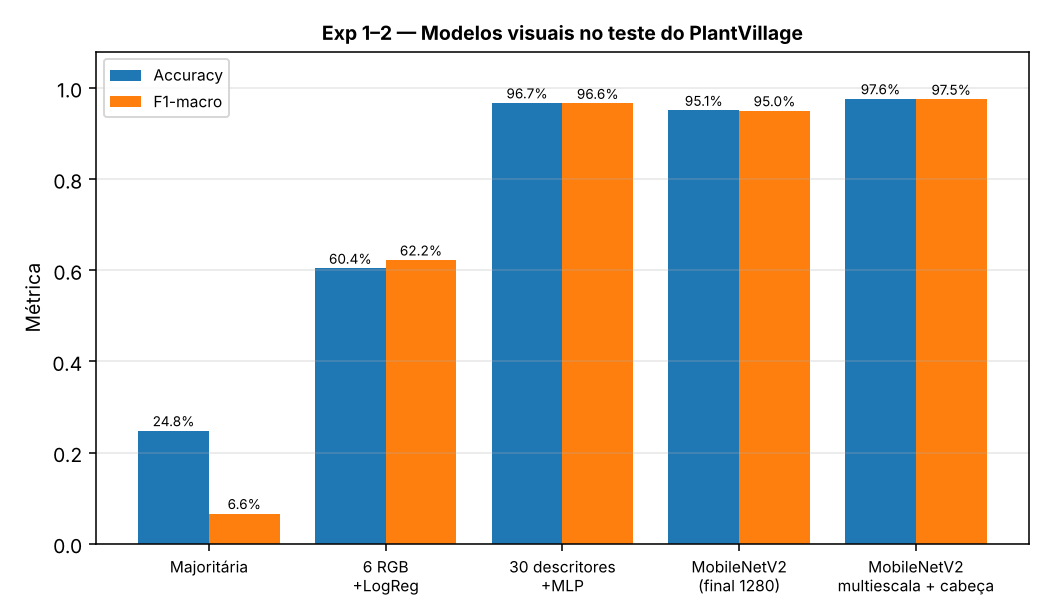

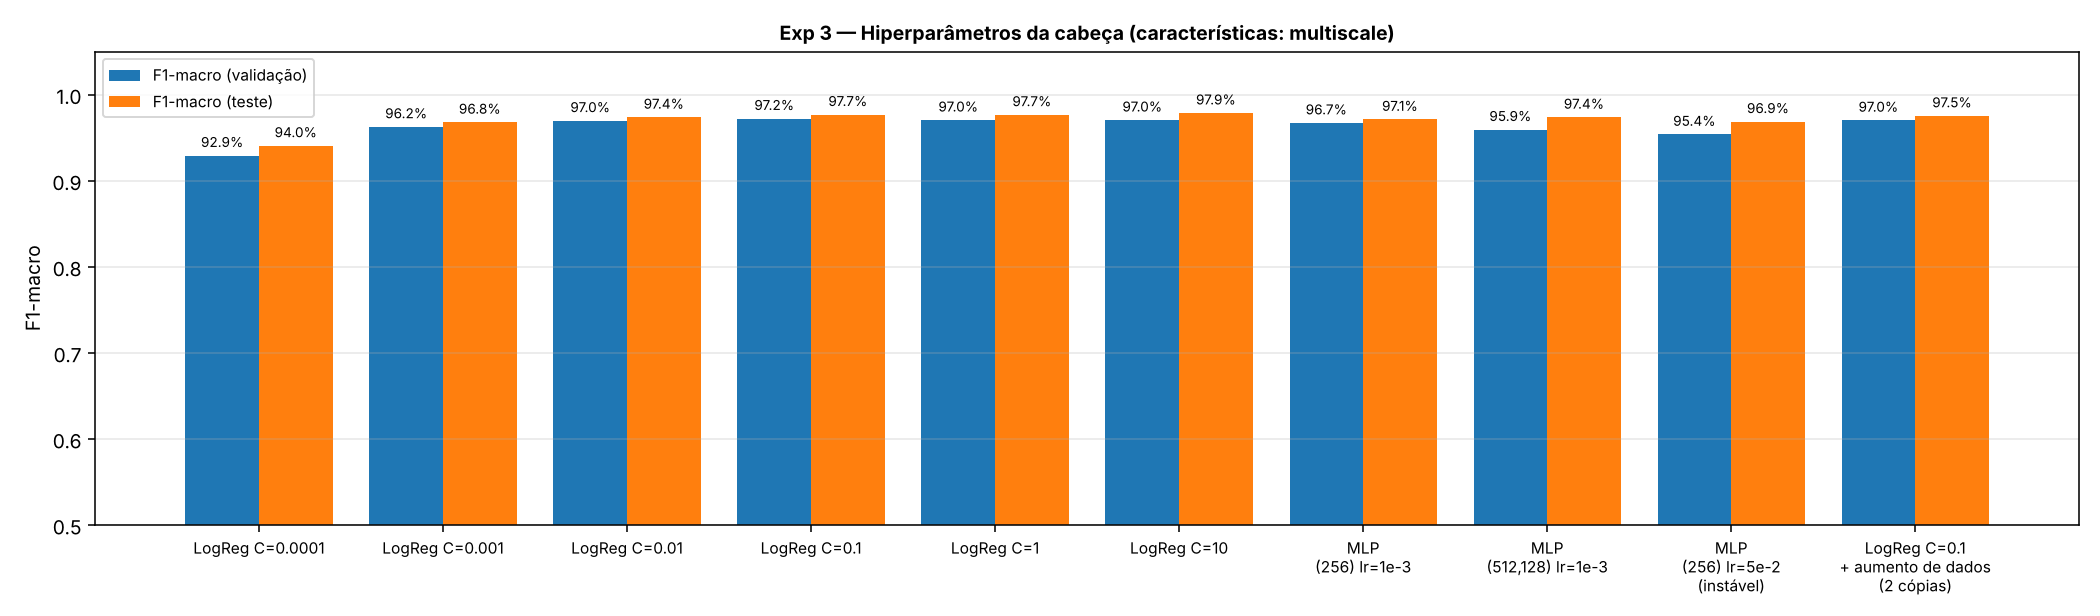

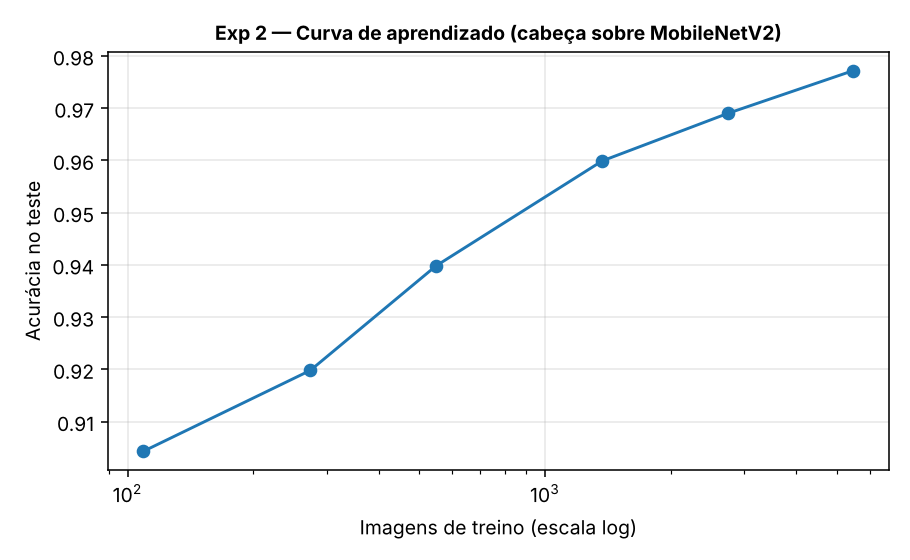

In [3]:
show('plots/exp2_model_comparison.png'); show('plots/exp3_hyperparameters.png'); show('plots/exp2_learning_curve.png')

In [4]:
# Recalcula ao vivo a cabeça logística (C=0.1) sobre as características em cache e confere com o JSON salvo
from src.ml import dataset as ds
from src.ml.run_all_experiments import make_head
from sklearn.metrics import accuracy_score, f1_score
recs, _ = ds.clean_records(ds.list_records(ds.PLANTVILLAGE_DIR)); sp = ds.split_70_15_15(recs)
F = ds.extract_features(recs, 'plantvillage_features'); y = F['labels']
m = make_head('logreg', c=0.1).fit(F['multiscale'][sp['train']], y[sp['train']]); p = m.predict(F['multiscale'][sp['test']])
print('Teste: acc=%.4f  F1-macro=%.4f' % (accuracy_score(y[sp['test']], p), f1_score(y[sp['test']], p, average='macro')))

Teste: acc=0.9772  F1-macro=0.9767


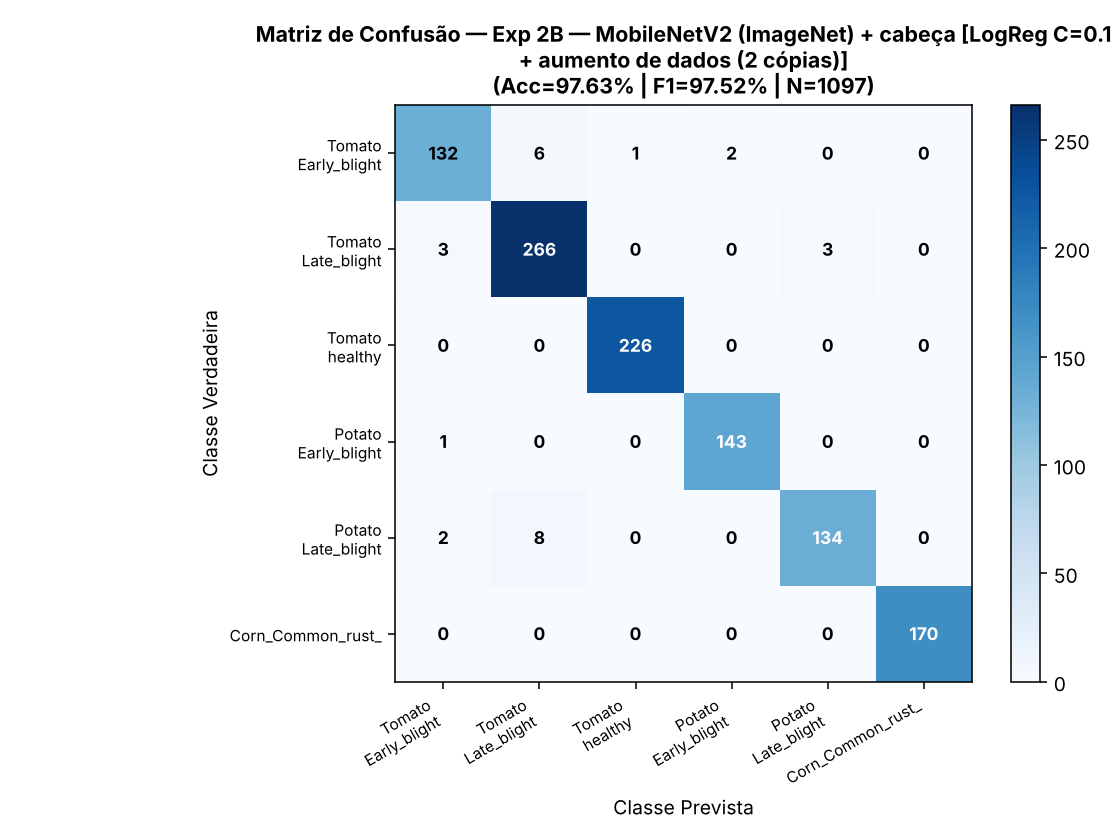

In [5]:
show('confusion_matrices/exp2_transfer_learning_cm.png')